# Task 1: Dataset Exploration and Understanding
Facial Feature Classification Challenge (ENGE707). Set the three paths in the next cell, then run all cells top to bottom. No Kaggle needed.

In [78]:
TRAIN_DIR = "train/train"
TEST_DIR = "test/test"
LABELS_CSV = "train_labels.csv"

SEED = 42
BLUR_SAMPLE = 2000

In [79]:
import hashlib, os, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

random.seed(SEED); np.random.seed(SEED)
EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def list_images(root):
    return [os.path.join(d, f) for d, _, fs in os.walk(root)
            for f in fs if os.path.splitext(f)[1].lower() in EXT]

def norm(x):
    """'00012' and '12' map to the same key."""
    x = os.path.splitext(str(x))[0]
    return x.lstrip("0") or "0"

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def sharpness(path):
    """Variance of a Laplacian on a 128x128 grayscale copy. Lower means blurrier."""
    g = np.asarray(Image.open(path).convert("L").resize((128, 128)), dtype=np.float32)
    lap = 4 * g[1:-1, 1:-1] - g[:-2, 1:-1] - g[2:, 1:-1] - g[1:-1, :-2] - g[1:-1, 2:]
    return float(lap.var())

## 1. Structure of the training and test data

In [80]:
def build_train_table():
    paths = list_images(TRAIN_DIR)
    if LABELS_CSV:
        lab = pd.read_csv(LABELS_CSV)
        id_col = lab.columns[0]
        cls_col = next(c for c in lab.columns if c.lower() in ("class", "label"))
        by_stem = {norm(os.path.basename(p)): p for p in paths}
        by_name = {os.path.basename(p): p for p in paths}
        rows = []
        for i, c in zip(lab[id_col].astype(str), lab[cls_col]):
            rows.append((by_name.get(i) or by_stem.get(norm(i)), c))
        df = pd.DataFrame(rows, columns=["path", "label"])
        if df["path"].isna().sum():
            print("WARNING: labelled ids with no image file:", int(df["path"].isna().sum()))
        return df.dropna()
    return pd.DataFrame({"path": paths, "label": [os.path.basename(os.path.dirname(p)) for p in paths]})

train = build_train_table()
test_paths = list_images(TEST_DIR)
print(f"Training images: {len(train)}   Test images: {len(test_paths)}")
files_all = {norm(os.path.basename(p)) for p in list_images(TRAIN_DIR)}
labelled = {norm(os.path.basename(p)) for p in train["path"]}
print("Image files with no label:", len(files_all - labelled), "  Labels with no image file:", len(labelled - files_all))
print("Classes:", sorted(train["label"].unique()))

Training images: 63660   Test images: 29443
Image files with no label: 0   Labels with no image file: 0
Classes: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']


## 2. Images per class and balance

,images,share_%
label,,
CatEye,13884,21.81
CatFace,6942,10.90
CatMouth,6942,10.90
CatNose,6942,10.90
DogEye,11580,18.19
DogFace,5790,9.10
DogMouth,5790,9.10
DogNose,5790,9.10


Largest / smallest ratio: 2.40  (largest CatEye = 13884, smallest DogFace = 5790)


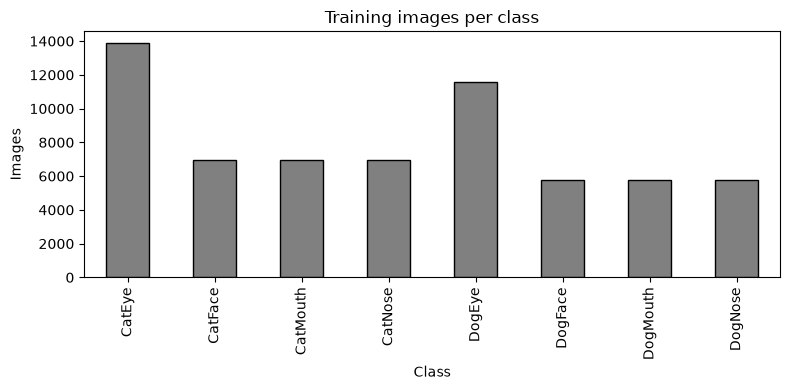

In [107]:
counts = train["label"].value_counts().sort_index()
summary = pd.DataFrame({"images": counts, "share_%": (100 * counts / counts.sum()).round(2)})
display(summary)
print(f"Largest / smallest ratio: {counts.max() / counts.min():.2f}  "
      f"(largest {counts.idxmax()} = {counts.max()}, smallest {counts.idxmin()} = {counts.min()})")

plt.figure(figsize=(8, 4))
counts.plot(kind="bar", color="gray", edgecolor="black")
plt.xlabel("Class"); 
plt.ylabel("Images"); 
plt.title("Training images per class"); plt.tight_layout(); plt.show()

## 3. Sample images from each class

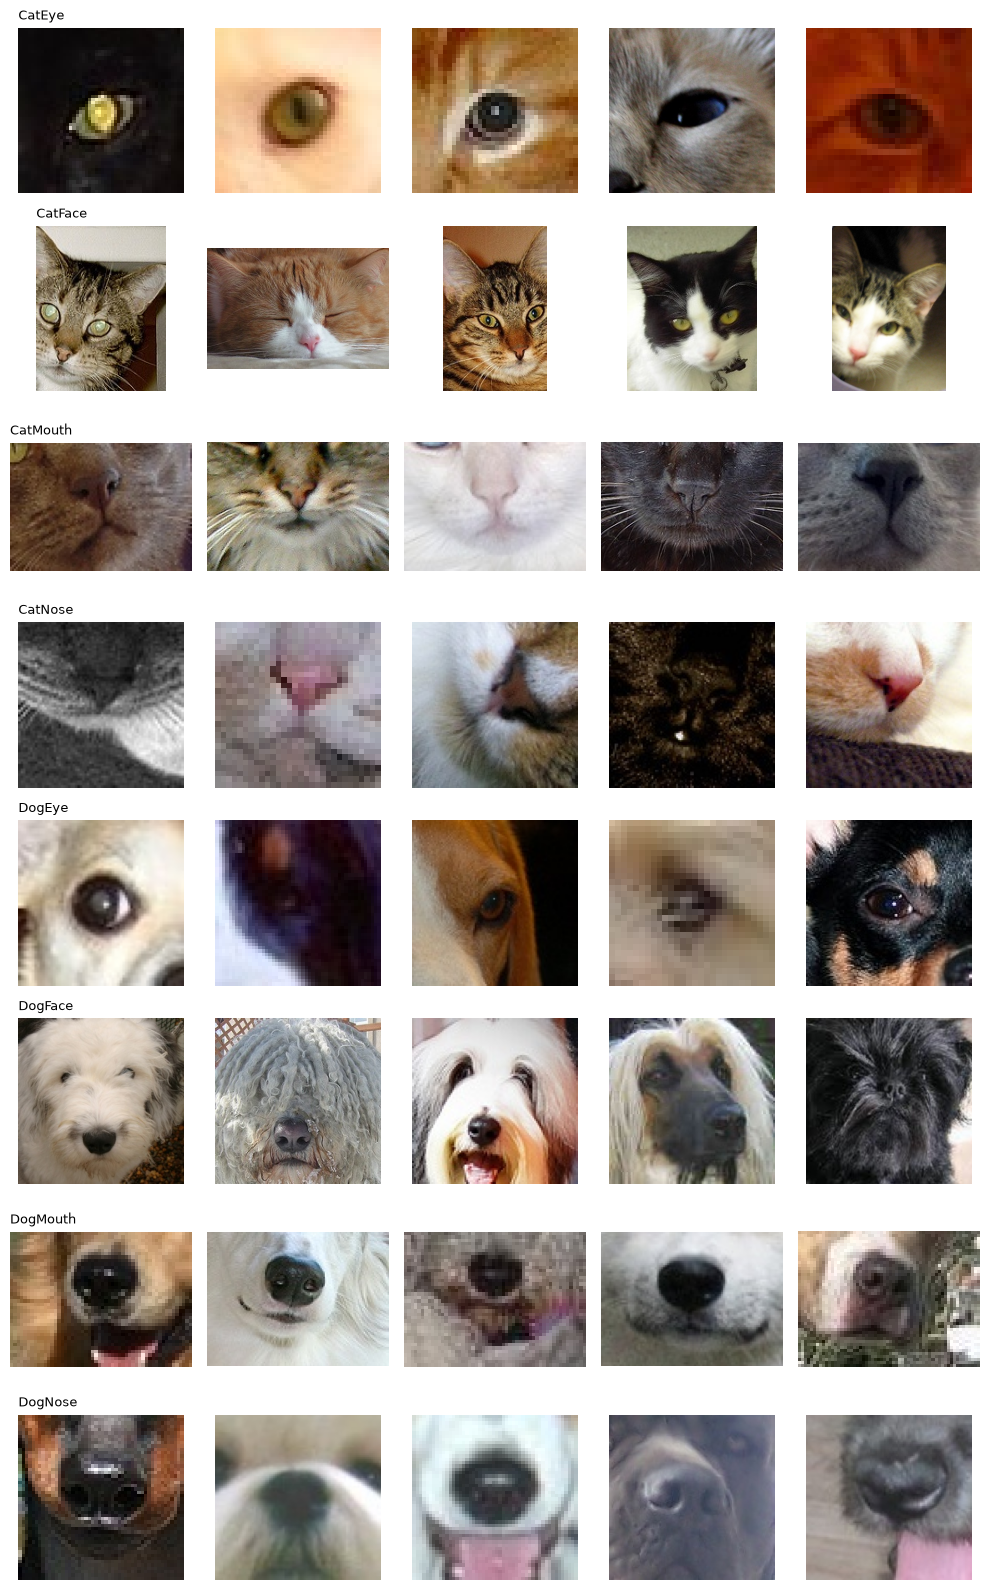

In [82]:
classes = list(counts.index)
fig, axes = plt.subplots(len(classes), 5, figsize=(10, 2 * len(classes)))
for r, c in enumerate(classes):
    picks = train[train["label"] == c].sample(min(5, counts[c]), random_state=SEED)["path"].tolist()
    for k in range(5):
        ax = axes[r][k]; ax.axis("off")
        if k < len(picks):
            ax.imshow(Image.open(picks[k]).convert("RGB"))
        if k == 0:
            ax.set_title(c, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## 4. Data quality: image sizes and corrupted file

Corrupted or unreadable training files: 0
Distinct image sizes: 7861   most common: [((40, 40), 1062), ((48, 48), 1051), ((42, 42), 1050), ((38, 38), 1002), ((44, 44), 1002)]
Width 4 to 2219,  height 4 to 2219


,w,h
label,,
CatEye,68.0,68.0
CatFace,182.0,215.0
CatMouth,114.0,80.0
CatNose,68.0,68.0
DogEye,62.0,62.0
DogFace,155.0,155.0
DogMouth,104.0,77.0
DogNose,62.0,62.0


Test images read: 29443 of 29443;  distinct sizes: 7786   most common: [((40, 40), 503), ((50, 50), 402), ((80, 80), 370), ((30, 30), 349), ((60, 60), 343)]
Test width 8 to 1832,  height 9 to 1978
TRAIN: shortest side median 78px, 5th pct 30px, min 4, max 2219;  under 32px: 4130 (6.5%),  under 64px: 23698 (37.2%),  under 112px: 44172 (69.4%)
TEST : shortest side median 77px, 5th pct 28px, min 8, max 1832;  under 32px: 2422 (8.2%),  under 64px: 11897 (40.4%),  under 112px: 20801 (70.6%)


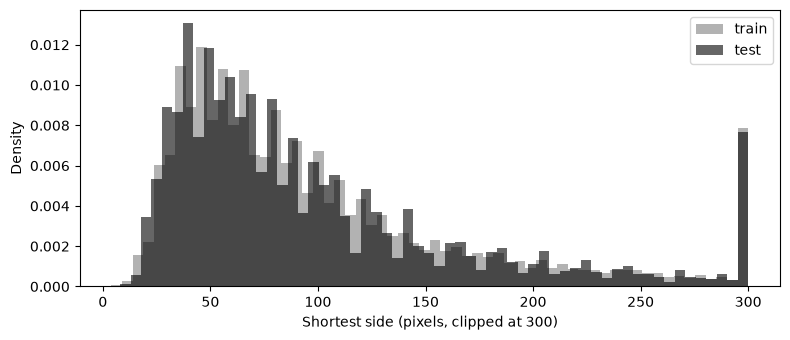

In [83]:
recs = []
for p, lab in zip(train["path"], train["label"]):
    rec = {"path": p, "label": lab, "w": None, "h": None, "corrupt": False, "md5": None}
    try:
        with Image.open(p) as im:
            rec["w"], rec["h"] = im.size
            im.verify()
        rec["md5"] = md5(p)
    except Exception:
        rec["corrupt"] = True
    recs.append(rec)
q = pd.DataFrame(recs)
ok = q[~q["corrupt"]].astype({"w": int, "h": int})

print("Corrupted or unreadable training files:", int(q["corrupt"].sum()))
sizes = Counter(zip(ok["w"], ok["h"]))
print(f"Distinct image sizes: {len(sizes)}   most common: {sizes.most_common(5)}")
print(f"Width {ok['w'].min()} to {ok['w'].max()},  height {ok['h'].min()} to {ok['h'].max()}")
display(ok.groupby("label")[["w", "h"]].median())

test_sizes = []
for p in test_paths:
    try:
        with Image.open(p) as im:
            test_sizes.append(im.size)
    except Exception:
        pass
tw = np.array([a for a, b in test_sizes]); th = np.array([b for a, b in test_sizes])
tsz = Counter(test_sizes)
print(f"Test images read: {len(test_sizes)} of {len(test_paths)};  distinct sizes: {len(tsz)}   most common: {tsz.most_common(5)}")
print(f"Test width {tw.min()} to {tw.max()},  height {th.min()} to {th.max()}")

def short_side_summary(w, h, name):
    sd = np.minimum(w, h)
    print(f"{name}: shortest side median {np.median(sd):.0f}px, 5th pct {np.percentile(sd, 5):.0f}px, min {sd.min()}, max {sd.max()};  "
          f"under 32px: {(sd < 32).sum()} ({100 * (sd < 32).mean():.1f}%),  under 64px: {(sd < 64).sum()} ({100 * (sd < 64).mean():.1f}%),  "
          f"under 112px: {(sd < 112).sum()} ({100 * (sd < 112).mean():.1f}%)")

short_side_summary(ok["w"].values, ok["h"].values, "TRAIN")
short_side_summary(tw, th, "TEST ")

plt.figure(figsize=(8, 3.5))
plt.hist(np.clip(np.minimum(ok["w"].values, ok["h"].values), 0, 300), bins=60, alpha=0.6, density=True, label="train", color="gray")
plt.hist(np.clip(np.minimum(tw, th), 0, 300), bins=60, alpha=0.6, density=True, label="test", color="black")
plt.xlabel("Shortest side (pixels, clipped at 300)"); plt.ylabel("Density"); plt.legend(); plt.tight_layout(); plt.show()

## 4b. Image size as a class signal

In [84]:
ok["short"] = np.minimum(ok["w"], ok["h"])
ok["aspect"] = ok["w"] / ok["h"]
by_class = ok.groupby("label").agg(
    median_w=("w", "median"), median_h=("h", "median"),
    median_shortest_side=("short", "median"),
    pct_under_64px=("short", lambda s: round(100 * (s < 64).mean(), 1)),
    median_aspect=("aspect", "median"))
display(by_class)
print(f"Square images (aspect ratio within 2% of 1): {100 * (abs(ok['aspect'] - 1) < 0.02).mean():.1f}%")
try:
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.model_selection import cross_val_score
    acc = cross_val_score(DecisionTreeClassifier(max_depth=8, random_state=SEED),
                          ok[["w", "h"]].values, ok["label"], cv=5, scoring="accuracy").mean()
    print(f"Accuracy from image width and height alone (5-fold): {acc:.4f}   "
          f"majority-class baseline: {ok['label'].value_counts(normalize=True).max():.4f}")
except ImportError:
    print("scikit-learn not installed, skipping the size-only baseline")

,median_w,median_h,median_shortest_side,pct_under_64px,median_aspect
label,,,,,
CatEye,68.0,68.0,68.0,45.6,1.000000
CatFace,182.0,215.0,178.0,4.7,0.827823
CatMouth,114.0,80.0,80.0,34.9,1.419355
CatNose,68.0,68.0,68.0,45.6,1.000000
DogEye,62.0,62.0,62.0,52.5,1.000000
DogFace,155.0,155.0,155.0,2.5,1.000000
DogMouth,104.0,77.0,77.0,37.7,1.353846
DogNose,62.0,62.0,62.0,52.5,1.000000


Square images (aspect ratio within 2% of 1): 69.0%
Accuracy from image width and height alone (5-fold): 0.4579   majority-class baseline: 0.2181


## 5. Data quality: duplicates

In [85]:
dup = ok[ok.duplicated("md5", keep=False)]
print(f"Exact duplicate files in training: {len(dup)} images in {dup['md5'].nunique()} groups")
if len(dup):
    conflict = int((dup.groupby("md5")["label"].nunique() > 1).sum())
    print("Duplicate groups with conflicting labels:", conflict)
    for _, g in list(dup.groupby("md5"))[:5]:
        print("  e.g.", [os.path.basename(p) for p in g["path"]], g["label"].iloc[0])

test_hashes = set()
for p in test_paths:
    try:
        test_hashes.add(md5(p))
    except Exception:
        pass
print("Training images identical to a test image:", int(ok["md5"].isin(test_hashes).sum()))

Exact duplicate files in training: 30 images in 15 groups
Duplicate groups with conflicting labels: 0
  e.g. ['30201.jpg', '50179.jpg'] DogEye
  e.g. ['03926.jpg', '56008.jpg'] CatEye
  e.g. ['49150.jpg', '55761.jpg'] DogEye
  e.g. ['35039.jpg', '55965.jpg'] DogFace
  e.g. ['45625.jpg', '54078.jpg'] DogFace
Training images identical to a test image: 0


## 6. Data quality: blur

Sharpness on 2000 sampled images: median 211.0, 5th percentile 7.3, min 1.8
Median sharpness, shortest side under 48px: 17.9 (n=431);  48px or more: 379.2 (n=1569)


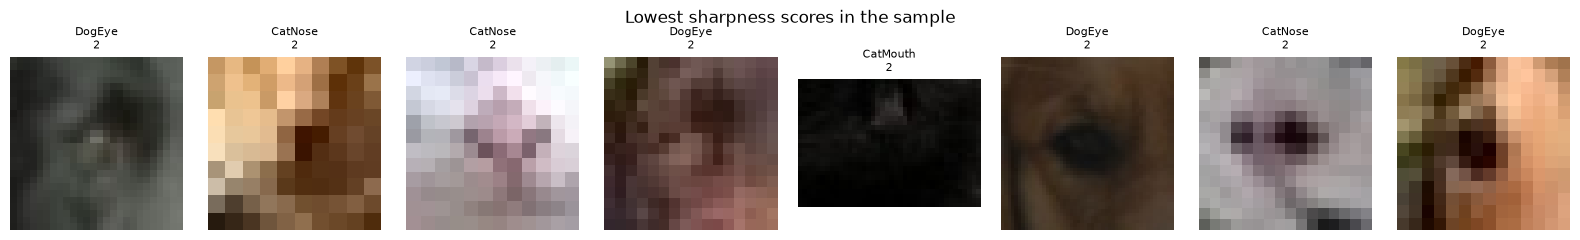

In [86]:
sample = ok.sample(min(BLUR_SAMPLE, len(ok)), random_state=SEED).copy()
sample["sharp"] = [sharpness(p) for p in sample["path"]]
print(f"Sharpness on {len(sample)} sampled images: median {sample['sharp'].median():.1f}, "
      f"5th percentile {sample['sharp'].quantile(0.05):.1f}, min {sample['sharp'].min():.1f}")

sample["short"] = np.minimum(sample["w"], sample["h"])
small, large = sample[sample["short"] < 48], sample[sample["short"] >= 48]
print(f"Median sharpness, shortest side under 48px: {small['sharp'].median():.1f} (n={len(small)});  48px or more: {large['sharp'].median():.1f} (n={len(large)})")

worst = sample.sort_values("sharp").head(8)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, (_, r) in zip(axes, worst.iterrows()):
    ax.imshow(Image.open(r["path"]).convert("RGB")); ax.axis("off")
    ax.set_title(f"{r['label']}\n{r['sharp']:.0f}", fontsize=8)
plt.suptitle("Lowest sharpness scores in the sample"); plt.tight_layout(); plt.show()

# Task 2: Data Preprocessing and Pipeline Preparation

First, resize all images to 96x96 RGB. This will be consistent with using pretrained ImageNet CNNs as well as Vision Transformers in the training process for transfer learning. From the Task 1 results, image size variation may encode some class information, so standardising to a square size will remove it as a direct input here. Second, normalise the images using the mean and standard deviation from ImageNet. These are standard constants and not learned from the dataset, so nothing is learned from the validation set or test set. They may be generalisable across different datasets. Also, label encode each label into a number 0-7 and keep the mapping between them so that the results can be translated back into the class. This could then be used to compare the predicted class vs the original class as in Task 5. Finally, ensure the split is stratified with an 80/20 split and keep exact duplicates grouped together. Stratifying means that the class proportions will be the same in the train/validation sets as in the original set, and then grouping the duplicates together will prevent them appearing in both sets, which will artificially inflate the validation accuracy. For the augmentation, only augment the training set and use mild transformations so that the class can still be seen.

In [87]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.model_selection import StratifiedGroupKFold

IMG_SIZE = 96
BATCH_SIZE = 64
VAL_FRACTION = 0.20
NUM_WORKERS = 0 if os.name == "nt" else 2      # 0 avoids multiprocessing problems on Windows notebooks
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
SUBMISSION_TEMPLATE = "sample_submission.csv"
SPLIT_FILE = "split.csv"

torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)

torch 2.14.1+cpu | device: cpu


## 1. Label encoding

In [88]:
classes = sorted(train["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
print(class_to_idx)

data = ok[["path", "label", "md5"]].reset_index(drop=True)
data["y"] = data["label"].map(class_to_idx)
print(f"{len(data)} readable labelled images (corrupt files were already excluded in Task 1)")

{'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}
63660 readable labelled images (corrupt files were already excluded in Task 1)


## 2. Train/validation split

In [89]:
n_splits = round(1 / VAL_FRACTION)
sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
train_idx, val_idx = next(sgkf.split(data, data["y"], groups=data["md5"]))
train_df = data.iloc[train_idx].reset_index(drop=True)
val_df = data.iloc[val_idx].reset_index(drop=True)

share = pd.DataFrame({
    "train_n": train_df["label"].value_counts().sort_index(),
    "val_n": val_df["label"].value_counts().sort_index()})
share["train_%"] = (100 * share["train_n"] / share["train_n"].sum()).round(2)
share["val_%"] = (100 * share["val_n"] / share["val_n"].sum()).round(2)
display(share)
print(f"Training: {len(train_df)} images ({100 * len(train_df) / len(data):.1f}%)   "
      f"Validation: {len(val_df)} images ({100 * len(val_df) / len(data):.1f}%)")
print(f"Largest class-share difference between the sets: {(share['train_%'] - share['val_%']).abs().max():.2f} percentage points")

# Save the split so every later task and every rerun uses exactly the same images
split = pd.concat([train_df.assign(split="train"), val_df.assign(split="val")])[["path", "label", "split"]]
split.to_csv(SPLIT_FILE, index=False)
print("Saved", SPLIT_FILE)

,train_n,val_n,train_%,val_%
label,,,,
CatEye,11107,2777,21.81,21.81
CatFace,5554,1388,10.91,10.90
CatMouth,5554,1388,10.91,10.90
CatNose,5553,1389,10.90,10.91
DogEye,9264,2316,18.19,18.19
DogFace,4632,1158,9.10,9.10
DogMouth,4632,1158,9.10,9.10
DogNose,4632,1158,9.10,9.10


Training: 50928 images (80.0%)   Validation: 12732 images (20.0%)
Largest class-share difference between the sets: 0.01 percentage points
Saved split.csv


## 3. Leakage checks

In [90]:
dup_groups = data[data.duplicated("md5", keep=False)]["md5"].nunique()
shared_hashes = set(train_df["md5"]) & set(val_df["md5"])
shared_paths = set(train_df["path"]) & set(val_df["path"])
print(f"Duplicate groups in the labelled data: {dup_groups}")
print("Identical files in both training and validation:", len(shared_hashes))
print("Image paths in both training and validation:", len(shared_paths))
assert not shared_hashes and not shared_paths, "leakage between training and validation"

val_dup_in_train = val_df["md5"].isin(set(train_df["md5"])).sum()
print("Validation images with an exact copy in training:", int(val_dup_in_train))
print("Normalisation constants are fixed ImageNet values, so no statistic is learned from validation or test images.")

Duplicate groups in the labelled data: 15
Identical files in both training and validation: 0
Image paths in both training and validation: 0
Validation images with an exact copy in training: 0
Normalisation constants are fixed ImageNet values, so no statistic is learned from validation or test images.


## 4. Transforms
The process of resizing is applied first to all images. Note that only the training transform adds augmentation. Mild transforms (including the horizontal flip) were deemed safe because face-shapes (mouth, nose, eyes, faces, etc.) are left-right symmetrical, and vertical flips and large rotations were not used because the images are all in the upright position. Small rotations, shifts, changes in scale, and brightness are hopefully mild enough that the images remain recognizable without the face-shape cues changing.

Task 1 results show that enlarging the small source images causes less clarity (median sharpness 17.9 for images under 48 px against 379.2 for larger ones), so the size cue is still 'faint' when the images are resized.

In [91]:
train_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = T.Compose([                       # used for BOTH validation and test images
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

## 5. Dataset objects and data loaders

In [92]:
class ImageDataset(Dataset):
    """Returns (image tensor, label) when labels are given, otherwise (image tensor, image_id)."""
    def __init__(self, paths, targets, transform):
        self.paths, self.targets, self.transform = list(paths), list(targets), transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            x = self.transform(im.convert("RGB"))
        return x, self.targets[i]

sub = pd.read_csv(SUBMISSION_TEMPLATE)
test_by_key = {norm(os.path.basename(p)): p for p in test_paths}
missing = [i for i in sub["image_id"] if norm(i) not in test_by_key]
assert not missing, f"{len(missing)} ids in {SUBMISSION_TEMPLATE} have no test image"
assert len(sub) == len(test_paths), (len(sub), len(test_paths))
test_ids = sub["image_id"].tolist()
test_files = [test_by_key[norm(i)] for i in test_ids]

train_ds = ImageDataset(train_df["path"], train_df["y"], train_tf)
val_ds = ImageDataset(val_df["path"], val_df["y"], eval_tf)
test_ds = ImageDataset(test_files, test_ids, eval_tf)

g = torch.Generator().manual_seed(SEED)
loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))
train_loader = DataLoader(train_ds, shuffle=True, generator=g, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)
print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)} images, batch size {BATCH_SIZE}")

train 50928 | val 12732 | test 29443 images, batch size 64


## 6. Checks on the finished pipeline

train batch: (64, 3, 96, 96)  dtype torch.float32  mean -0.19  std 1.23  min -2.12  max +2.64
val   batch: (64, 3, 96, 96)  dtype torch.float32  mean -0.10  std 1.11  min -2.12  max +2.64
test  batch: (64, 3, 96, 96)  dtype torch.float32  mean -0.06  std 1.10  min -2.12  max +2.64


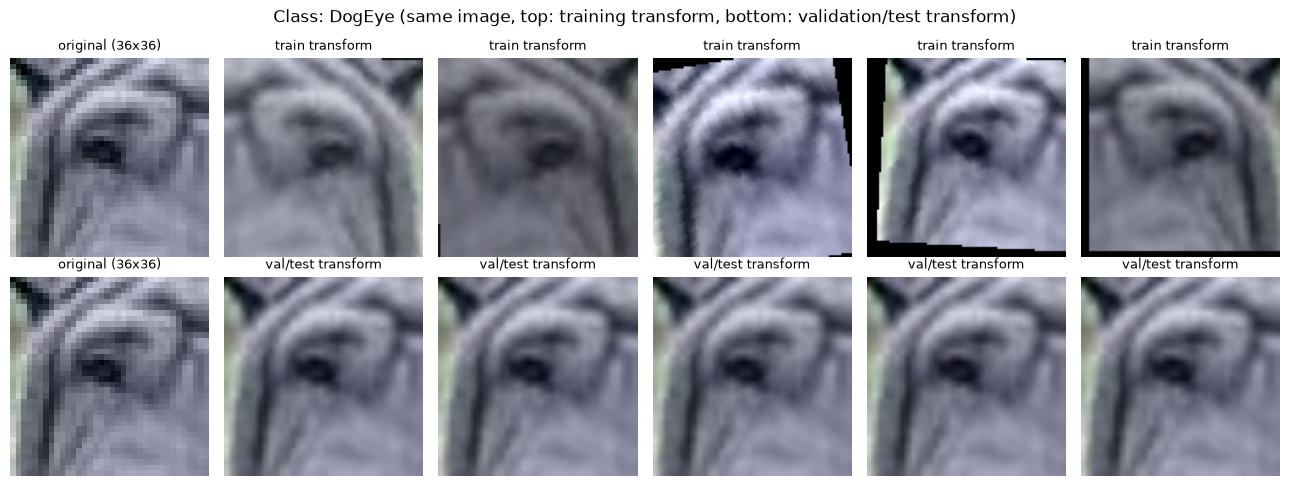

In [93]:
assert val_ds.transform is test_ds.transform, "validation and test must share one transform"
for name, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
        xb, yb = next(iter(loader))
        print(f"{name:5s} batch: {tuple(xb.shape)}  dtype {xb.dtype}  "
          f"mean {xb.mean():+.2f}  std {xb.std():.2f}  min {xb.min():+.2f}  max {xb.max():+.2f}")

def denorm(x):
    m = torch.tensor(IMAGENET_MEAN).view(3, 1, 1); s = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

# The same file through both transforms: training draws differ each time, validation/test is always the plain resize
i = 0
same_file = train_df["path"][i]
rows = [("train transform", ImageDataset([same_file], [0], train_tf)),
        ("val/test transform", ImageDataset([same_file], [0], eval_tf))]
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
orig = Image.open(same_file).convert("RGB")
for r, (title, ds) in enumerate(rows):
    axes[r][0].imshow(orig); axes[r][0].set_title(f"original ({orig.size[0]}x{orig.size[1]})", fontsize=9)
    for k in range(1, 6):
        axes[r][k].imshow(denorm(ds[0][0])); axes[r][k].set_title(title, fontsize=9)
    for a in axes[r]:
        a.axis("off")
plt.suptitle(f"Class: {train_df['label'][i]} (same image, top: training transform, bottom: validation/test transform)")
plt.tight_layout(); plt.show()

# Task 3: Model Selection and Pipeline Development

Note that the Task 1 and Task 2 cells must be run before this section. This section reuses `classes`, `idx_to_class`, `train_ds`, `val_ds`, `test_ds`, `sub`, `device` and `IMG_SIZE`.

Decisions, with the reason for each:
- **Model: ResNet-18 (pre-trained on ImageNet, transfer learning)**. A residual CNN with 11M parameters, which is quite small compared to other models and thus can be trained quite fast on a laptop CPU. The edges, textures and shapes of other images learned by the network on ImageNet can also be expected to transfer to images of cats' and dogs' faces. A Vision Transformer like ViT-B/16 (86M parameters) would be much slower to run on a CPU and would expect input of size 224x224. A custom CNN would also need to be trained from scratch and would likely require more epochs and more data to converge than the pre-trained ResNet.
- **Input and output:** The input to the network is 3x96x96 from Task 2. The final fully connected layer is replaced by a linear layer with 8 outputs, one for each class. ReLU activation is used inside the network. The output layer has no activation so it returns raw scores (logits) and a softmax is applied in the loss function during training.
- **Loss: cross-entropy.** Because the task is single-label classification with 8 classes.
- **Optimiser: AdamW with 3e-4 learning rate and 1e-4 weight decay.** A low learning rate changes the pretrained weights slowly rather than breaking them, and AdamW adapts the step size for every weight.
- **Batch size 32.** 32 is a common choice, which is good enough to get stable gradient estimates without consuming too much RAM.
- **Number of epochs for the baseline run:** 5, as the run is on a laptop CPU. The learning curves can be used in Task 4 to adjust the number of epochs if required.

Only the last residual block (layer4) and the new output layer are trained, and the earlier layers stay frozen. The earlier layers detect general edges and textures that transfer well, and freezing them reduced the measured time per epoch on the laptop CPU from about 33 minutes to about 18 minutes.

In [94]:
import copy, time
import torch.nn as nn
from torch.utils.data import Subset
from torchvision import models

MODEL_NAME = "resnet18"
PRETRAINED = True               # ImageNet weights (downloaded once on first use)
NUM_CLASSES = len(classes)
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
TRAIN_BATCH_SIZE = 32
EPOCHS = 5
DEBUG_N = None                  # set to e.g. 512 to test the whole pipeline on a tiny subset first
BEST_WEIGHTS = "best_model.pt"
SUBMISSION_FILE = "submission.csv"
HISTORY_FILE = "history.csv"
use_amp = (device == "cuda")    # mixed precision is only switched on when a GPU is used
torch.set_num_threads(6)

## 1. Model

In [108]:
def build_model():
    weights = models.ResNet18_Weights.DEFAULT if PRETRAINED else None
    m = models.resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)      # new 8-class output layer
    for name, p in m.named_parameters():                 # train only the last block and the new output layer
        if not name.startswith(("layer4", "fc")):
            p.requires_grad = False
    return m

model = build_model().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.2f}M of {n_params / 1e6:.2f}M")
print(f"{MODEL_NAME}: {n_params / 1e6:.1f}M parameters, pretrained={PRETRAINED}, device={device}")
print("Output layer:", model.fc)

with torch.no_grad():
    out = model.eval()(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=device))
print("Input (2, 3, %d, %d) -> output" % (IMG_SIZE, IMG_SIZE), tuple(out.shape))
assert out.shape == (2, NUM_CLASSES)

Trainable parameters: 8.40M of 11.18M
resnet18: 11.2M parameters, pretrained=True, device=cpu
Output layer: Linear(in_features=512, out_features=8, bias=True)
Input (2, 3, 96, 96) -> output (2, 8)


## 2. Data loaders for training

In [96]:
def make_loader(ds, shuffle, seed=SEED):
    if DEBUG_N:
        ds = Subset(ds, range(min(DEBUG_N, len(ds))))
    gen = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(ds, batch_size=TRAIN_BATCH_SIZE, shuffle=shuffle, generator=gen,
                      num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))

fit_train_loader = make_loader(train_ds, shuffle=True)
fit_val_loader = make_loader(val_ds, shuffle=False)
fit_test_loader = make_loader(test_ds, shuffle=False)
print(f"batches per epoch: train {len(fit_train_loader)}, val {len(fit_val_loader)}, test {len(fit_test_loader)}"
      f"  (batch size {TRAIN_BATCH_SIZE})" + ("  [DEBUG subset]" if DEBUG_N else ""))

batches per epoch: train 1592, val 398, test 921  (batch size 32)


## 3. Training pipeline

In [110]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    """One pass over a loader. Trains when an optimiser is given, otherwise only evaluates."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            with torch.autocast(device_type=device, enabled=use_amp):
                logits = model(xb)
                loss = criterion(logits, yb)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(1) == yb).sum().item()
            n += xb.size(0)
    return total_loss / n, correct / n


def train_model(model, train_loader, val_loader, epochs, lr, weight_decay,
                scheduler_fn=None, patience=None, weights_file=BEST_WEIGHTS):
    """Trains, records the learning curves, keeps the weights with the best validation accuracy.
    scheduler_fn and patience are optional so the same function can be reused in Task 4."""
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = scheduler_fn(optimizer) if scheduler_fn else None
    scaler = torch.amp.GradScaler(device, enabled=use_amp)
    history, best_acc, bad_epochs = [], 0.0, 0
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        if scheduler:
            scheduler.step()
        history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc,
                            lr=optimizer.param_groups[0]["lr"], seconds=time.time() - t0))
        improved = va_acc > best_acc
        if improved:
            best_acc, bad_epochs = va_acc, 0
            torch.save(model.state_dict(), weights_file)
        else:
            bad_epochs += 1
        print(f"epoch {epoch:2d}/{epochs}  train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | {time.time() - t0:.0f}s" + ("  *best*" if improved else ""))
        if patience and bad_epochs >= patience:
            print(f"early stopping: no validation improvement for {patience} epochs")
            break
    return pd.DataFrame(history)

## 4. Speed check

In [ ]:
# Times a few training batches on a throwaway copy of the model to estimate the length of one epoch
probe = copy.deepcopy(model).train()
probe_opt = torch.optim.AdamW(probe.parameters(), lr=LEARNING_RATE)
probe_scaler = torch.amp.GradScaler(device, enabled=use_amp)
n_probe, t0 = 0, None
for i, (xb, yb) in enumerate(fit_train_loader):
    if i == 2:                       # skip the first batches (warm-up)
        if device == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()
    xb, yb = xb.to(device), yb.to(device)
    with torch.autocast(device_type=device, enabled=use_amp):
        loss = nn.functional.cross_entropy(probe(xb), yb)
    probe_opt.zero_grad(set_to_none=True)
    probe_scaler.scale(loss).backward(); probe_scaler.step(probe_opt); probe_scaler.update()
    if i >= 2:
        n_probe += 1
    if i == 11 or i == len(fit_train_loader) - 1:
        break
if device == "cuda":
    torch.cuda.synchronize()
if n_probe:
    per_batch = (time.time() - t0) / n_probe
    print(f"{per_batch:.2f}s per batch -> about {per_batch * len(fit_train_loader) / 60:.1f} min per training epoch "
          f"(plus validation), about {per_batch * len(fit_train_loader) * EPOCHS / 60:.0f} min for {EPOCHS} epochs")
if device == "cuda":
    print(f"peak GPU memory: {torch.cuda.max_memory_allocated() / 2**30:.2f} GiB of {torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB")
del probe, probe_opt

0.42s per batch -> about 11.2 min per training epoch (plus validation), about 56 min for 5 epochs


## 5. Train

In [99]:
model = build_model().to(device)          # fresh model so the speed check does not affect training
history = train_model(model, fit_train_loader, fit_val_loader, EPOCHS, LEARNING_RATE, WEIGHT_DECAY)
history.to_csv(HISTORY_FILE, index=False)
display(history.round(4))
print(f"Best validation accuracy: {history['val_acc'].max():.4f} (epoch {int(history['val_acc'].idxmax()) + 1})")

epoch  1/5  train loss 0.1807 acc 0.9371 | val loss 0.0605 acc 0.9790 | 773s  *best*
epoch  2/5  train loss 0.0913 acc 0.9680 | val loss 0.0403 acc 0.9863 | 772s  *best*
epoch  3/5  train loss 0.0720 acc 0.9752 | val loss 0.0456 acc 0.9841 | 773s
epoch  4/5  train loss 0.0603 acc 0.9789 | val loss 0.0564 acc 0.9819 | 766s
epoch  5/5  train loss 0.0575 acc 0.9810 | val loss 0.0355 acc 0.9878 | 764s  *best*


,epoch,train_loss,train_acc,val_loss,val_acc,lr,seconds
0,1,0.1807,0.9371,0.0605,0.9790,0.0003,773.1600
1,2,0.0913,0.9680,0.0403,0.9863,0.0003,771.7583
2,3,0.0720,0.9752,0.0456,0.9841,0.0003,772.6040
3,4,0.0603,0.9789,0.0564,0.9819,0.0003,766.2252
4,5,0.0575,0.9810,0.0355,0.9878,0.0003,763.9614


Best validation accuracy: 0.9878 (epoch 5)


## 6. Predictions for the Kaggle test set


In [100]:
model.load_state_dict(torch.load(BEST_WEIGHTS, map_location=device))   # weights from the best validation epoch
model.eval()

@torch.no_grad()
def predict(model, loader):
    ids, preds = [], []
    for xb, id_batch in loader:
        with torch.autocast(device_type=device, enabled=use_amp):
            logits = model(xb.to(device, non_blocking=True))
        preds += logits.argmax(1).cpu().tolist()
        ids += [int(i) for i in id_batch]
    return ids, preds

test_ids_out, test_preds = predict(model, fit_test_loader)
submission = pd.DataFrame({"image_id": test_ids_out, "class": [idx_to_class[p] for p in test_preds]})

if not DEBUG_N:
    assert list(submission.columns) == list(sub.columns), "columns must match the sample submission"
    assert submission["image_id"].tolist() == sub["image_id"].tolist(), "ids must match the sample submission order"
    assert set(submission["class"]) <= set(classes)
submission.to_csv(SUBMISSION_FILE, index=False)
print(f"Saved {SUBMISSION_FILE}: {len(submission)} rows" + ("  [DEBUG subset, not for Kaggle]" if DEBUG_N else ""))
display(submission.head())
print(submission["class"].value_counts())

Saved submission.csv: 29443 rows


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogNose
3,4,DogFace
4,5,CatMouth


class
CatEye      6518
DogEye      5404
CatMouth    3220
CatFace     3122
CatNose     2871
DogMouth    2817
DogFace     2789
DogNose     2702
Name: count, dtype: int64


# Task 4: Training Strategy and Overfitting/Underfitting Management

Run the Task 1, Task 2 and Task 3 cells in this order. The Training cell for the Task 3 can be skipped if history.csv has already been saved (i.e., the baseline curves have already been saved and read from history.csv). This section essentially just reuses code from the Task 3 section including the settings for the Task: train_model, fit_train_loader, fit_val_loader, fit_test_loader, classes, idx_to_class, sub, and device.

First, the results of the baseline run in Task 3 are analyzed. Then, an improvement run is trained and compared to the above run.

In [101]:
from torch.optim.lr_scheduler import CosineAnnealingLR

EPOCHS_T4 = 5                           # same number of epochs as the baseline, so the two runs are comparable
LEARNING_RATE_T4 = 3e-4                 # same starting learning rate as the baseline
WEIGHT_DECAY_T4 = 1e-4
PATIENCE = 2                            # stop if validation accuracy has not improved for 2 epochs
UNFREEZE = ("layer3", "layer4", "fc")   # parts of ResNet-18 that are trained in this run
BEST_WEIGHTS_T4 = "best_model_task4.pt"
HISTORY_FILE_T4 = "history_task4.csv"
SUBMISSION_FILE_T4 = "submission_task4.csv"

## 1. Baseline learning curves

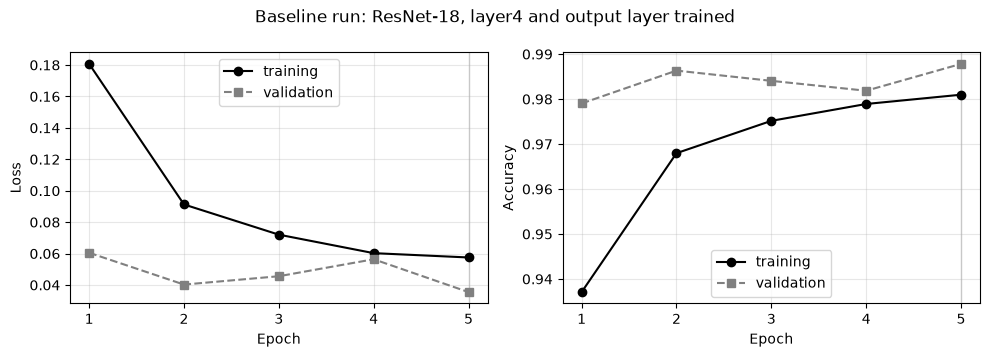

Baseline: best validation accuracy 0.9878 (epoch 5), final training accuracy 0.9810, final validation accuracy 0.9878 (training minus validation: -0.69 points)
   training loss fell in every epoch: True;  validation loss rose in epochs: [3, 4]


In [ ]:
history_base = pd.read_csv(HISTORY_FILE)

def plot_history(hist, title):
    """Loss (left) and accuracy (right) for training and validation. The grey line marks the best validation epoch."""
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ep = list(hist["epoch"])
    ax[0].plot(ep, hist["train_loss"], color="black", marker="o", label="training")
    ax[0].plot(ep, hist["val_loss"], color="gray", marker="s", linestyle="--", label="validation")
    ax[0].set_ylabel("Loss")
    ax[1].plot(ep, hist["train_acc"], color="black", marker="o", label="training")
    ax[1].plot(ep, hist["val_acc"], color="gray", marker="s", linestyle="--", label="validation")
    ax[1].set_ylabel("Accuracy")
    best_epoch = hist.loc[hist["val_acc"].idxmax(), "epoch"]
    for a in ax:
        a.axvline(best_epoch, color="lightgray", linewidth=1, zorder=0)
        a.set_xlabel("Epoch"); a.set_xticks(ep); a.grid(alpha=0.3); a.legend()
    plt.suptitle(title); plt.tight_layout(); plt.show()

def summarise(hist, name):
    e, tl, vl = hist["epoch"].to_numpy(), hist["train_loss"].to_numpy(), hist["val_loss"].to_numpy()
    last, best = hist.iloc[-1], hist.loc[hist["val_acc"].idxmax()]
    rose = [int(e[i]) for i in range(1, len(vl)) if vl[i] > vl[i - 1]]
    print(f"{name}: best validation accuracy {best['val_acc']:.4f} (epoch {int(best['epoch'])}), "
          f"final training accuracy {last['train_acc']:.4f}, final validation accuracy {last['val_acc']:.4f} "
          f"(training minus validation: {100 * (last['train_acc'] - last['val_acc']):+.2f} points)")
    print(f"   training loss fell in every epoch: {bool((tl[1:] < tl[:-1]).all())};  validation loss rose in epochs: {rose or 'none'}")

plot_history(history_base, "Baseline run: ResNet-18, layer4 and output layer trained")
summarise(history_base, "Baseline")

### Reading the baseline curves

Training accuracy was increased to 98.1% and training loss decreased in every epoch from 0.181 to 0.058. Validation accuracy was increased to the best value of 98.78% in epoch 5 and validation loss was decreased to the lowest value of 0.0355 in epoch 5.

- **No clear overfitting.** Although validation loss increased slightly in epochs 3 and 4, it has decreased again in the last epoch and training accuracy is far above validation accuracy in all epochs.
- **Validation above training is expected.** Since training accuracy and loss are averaged over the epoch in which the weights are still changing (and the input images are also augmented), it is expected to be below the accuracy and loss measured on clean images in validation using the fixed weights at the end of the epoch.
- **Possible mild underfitting.** Training loss is still decreasing in epoch 5, and the best validation accuracy has been found in the last epoch. This would suggest that there is still potential for improvement. However, the part of the network that is trainable (`layer4` and the output layer) can only change so much in order to optimize the network to this particular dataset.
- **Noisy validation loss.** By the later epochs the constant learning rate used here would probably have become too high.

The baseline submission scored 0.9662 on the public Kaggle leaderboard, a generalisation gap of 2.2% to the images left on test that the validation curves cannot show. This will be revisited in Tasks 5 and 6.

## 2. Strategies applied

No overfitting in the curves above. Hence the focus is on dealing with the underfitting and the noise in the validation loss curves as opposed to adding more regularization.

- **Learning-rate scheduling (cosine annealing)**: Training starts with a learning rate of 3e-4 and then decreases smoothly towards 0 in the course of the 5 epochs. That way, large steps can be taken in the first part of training, and in the later phase of training, small steps are taken in order to prevent strong fluctuations of the validation loss.
- **Fine-tuning `layer3` as well as `layer4`**: Training loss was still falling and there was no overfitting, so there was room to add capacity. Adapting `layer3` features that are more specific to cat and dog facial features than the ones found in `layer1` and `layer2` features should be more effective than adapting the early layers of the network. The backward pass now reaches `layer3`, which makes each epoch of the training even slower.
- **Early stopping (patience 2) with best-validation weights.** To make sure it's not overfitting the new unfrozen weights, we’ll keep track of the highest validation accuracy and the corresponding model weights.
- **Weight decay of 1e-4 (AdamW)**: Same as in the baseline solution.
- **Training-only augmentation**: Same as in the baseline solution.
- **Batch normalization**: Present in the ResNet-18 model and in the baseline solution.
- **Pre-trained ImageNet weights**: Present in the ResNet-18 model and in the baseline solution.
- **Not added**: In this modification of the baseline no attempt has been made to add dropout and other regularisation techniques. Likewise, no attempt has been made to increase the degree of augmentation used for training in order to try to combat possible underfitting, as the overfitting is already being dealt with in a less than optimal manner.

Note that in order to test new parts of the code separately would take too long on a laptop CPU. Therefore, we test the scheduler and the new unfrozen layer together in one run. The results therefore cannot be attributed to one of the two changes alone.

In [103]:
def build_finetune_model():
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if PRETRAINED else None)
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    for name, p in m.named_parameters():
        p.requires_grad = name.startswith(UNFREEZE)      # train only the listed parts
    return m

torch.manual_seed(SEED)
model_t4 = build_finetune_model().to(device)
trainable = sum(p.numel() for p in model_t4.parameters() if p.requires_grad)
total = sum(p.numel() for p in model_t4.parameters())
print(f"Trainable parameters: {trainable / 1e6:.2f}M of {total / 1e6:.2f}M  (parts trained: {', '.join(UNFREEZE)})")

Trainable parameters: 10.50M of 11.18M  (parts trained: layer3, layer4, fc)


## 3. Train the improvement run

epoch  1/5  train loss 0.1305 acc 0.9555 | val loss 0.0325 acc 0.9894 | 868s  *best*
epoch  2/5  train loss 0.0609 acc 0.9797 | val loss 0.0282 acc 0.9904 | 829s  *best*
epoch  3/5  train loss 0.0391 acc 0.9868 | val loss 0.0260 acc 0.9910 | 835s  *best*
epoch  4/5  train loss 0.0243 acc 0.9918 | val loss 0.0212 acc 0.9928 | 834s  *best*
epoch  5/5  train loss 0.0144 acc 0.9951 | val loss 0.0152 acc 0.9947 | 845s  *best*


,epoch,train_loss,train_acc,val_loss,val_acc,lr,seconds
0,1,0.1305,0.9555,0.0325,0.9894,0.000300,867.5191
1,2,0.0609,0.9797,0.0282,0.9904,0.000271,829.1340
2,3,0.0391,0.9868,0.0260,0.9910,0.000196,835.2513
3,4,0.0243,0.9918,0.0212,0.9928,0.000104,833.7139
4,5,0.0144,0.9951,0.0152,0.9947,0.000029,844.6197


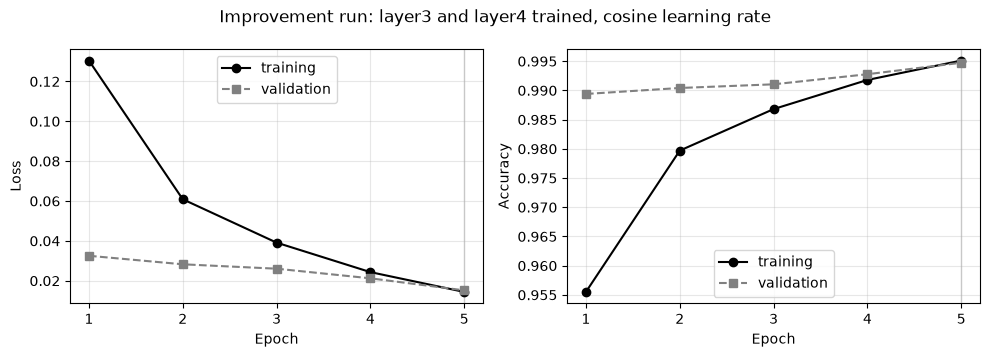

Improvement run: best validation accuracy 0.9947 (epoch 5), final training accuracy 0.9951, final validation accuracy 0.9947 (training minus validation: +0.04 points)
   training loss fell in every epoch: True;  validation loss rose in epochs: none


In [ ]:
history_t4 = train_model(model_t4, fit_train_loader, fit_val_loader, EPOCHS_T4, LEARNING_RATE_T4, WEIGHT_DECAY_T4,
    scheduler_fn=lambda opt: CosineAnnealingLR(opt, T_max=EPOCHS_T4),
    patience=PATIENCE, weights_file=BEST_WEIGHTS_T4)
# train_model records the learning rate after the scheduler step, so shift it by one epoch
# to show the rate that each epoch was actually trained with
history_t4["lr"] = [LEARNING_RATE_T4] + history_t4["lr"].tolist()[:-1]
history_t4.to_csv(HISTORY_FILE_T4, index=False)
display(history_t4.round(4).assign(lr=history_t4["lr"].map("{:.6f}".format)))
plot_history(history_t4, "Improvement run: layer3 and layer4 trained, cosine learning rate")
summarise(history_t4, "Improvement run")

## 4. Comparison with the baseline

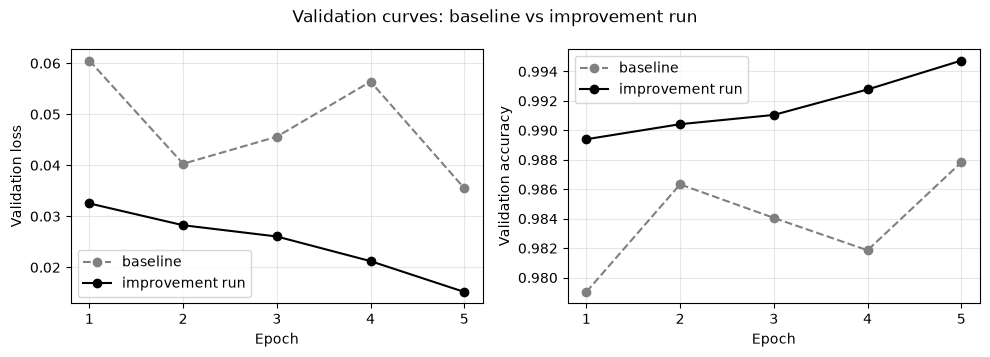

,run,best epoch,best val acc,val loss at best epoch,train acc at best epoch,minutes per epoch
0,"baseline (layer4 + fc, constant LR)",5,0.9878,0.0355,0.9810,12.8
1,"improvement (layer3 + layer4 + fc, cosine LR)",5,0.9947,0.0152,0.9951,14.0


In [105]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for hist, name, colour, style in [(history_base, "baseline", "gray", "--"), (history_t4, "improvement run", "black", "-")]:
    ax[0].plot(hist["epoch"], hist["val_loss"], color=colour, linestyle=style, marker="o", label=name)
    ax[1].plot(hist["epoch"], hist["val_acc"], color=colour, linestyle=style, marker="o", label=name)
ax[0].set_ylabel("Validation loss"); ax[1].set_ylabel("Validation accuracy")
for a in ax:
    a.set_xlabel("Epoch"); a.set_xticks(range(1, max(len(history_base), len(history_t4)) + 1)); a.grid(alpha=0.3); a.legend()
plt.suptitle("Validation curves: baseline vs improvement run"); plt.tight_layout(); plt.show()

def row(hist, name):
    best = hist.loc[hist["val_acc"].idxmax()]
    return {"run": name, "best epoch": int(best["epoch"]), "best val acc": round(best["val_acc"], 4),
            "val loss at best epoch": round(best["val_loss"], 4), "train acc at best epoch": round(best["train_acc"], 4),
            "minutes per epoch": round(hist["seconds"].mean() / 60, 1)}

display(pd.DataFrame([row(history_base, "baseline (layer4 + fc, constant LR)"),
    row(history_t4, f"improvement ({' + '.join(UNFREEZE)}, cosine LR)")]))

## 5. Predictions from the improvement run

In [106]:
WRITE_SUBMISSION_T4 = True

@torch.no_grad()
def predict_test(model, loader):
    model.eval()
    ids, preds = [], []
    for xb, id_batch in loader:
        with torch.autocast(device_type=device, enabled=use_amp):
            logits = model(xb.to(device, non_blocking=True))
        preds += logits.argmax(1).cpu().tolist()
        ids += [int(i) for i in id_batch]
    return ids, preds

if WRITE_SUBMISSION_T4:
    model_t4.load_state_dict(torch.load(BEST_WEIGHTS_T4, map_location=device))   # best validation epoch of this run
    ids_t4, preds_t4 = predict_test(model_t4, fit_test_loader)
    submission_t4 = pd.DataFrame({"image_id": ids_t4, "class": [idx_to_class[p] for p in preds_t4]})
    if not DEBUG_N:
        assert list(submission_t4.columns) == list(sub.columns), "columns must match the sample submission"
        assert submission_t4["image_id"].tolist() == sub["image_id"].tolist(), "ids must match the sample submission order"
        assert set(submission_t4["class"]) <= set(classes)
    submission_t4.to_csv(SUBMISSION_FILE_T4, index=False)
    print(f"Saved {SUBMISSION_FILE_T4}: {len(submission_t4)} rows" + ("  [DEBUG subset, not for Kaggle]" if DEBUG_N else ""))
    print(f"Best validation accuracy: baseline {history_base['val_acc'].max():.4f}, improvement run {history_t4['val_acc'].max():.4f}")

Saved submission_task4.csv: 29443 rows
Best validation accuracy: baseline 0.9878, improvement run 0.9947


# Task 5: Model Evaluation and Kaggle Submission

Run task 1 to 4 first

Decisions, with the reason for each:
- **Final model: the improvement run from Task 4.** The weights of this model have been saved, so the improvement of the accuracy can be checked again with the corresponding epoch (where highest validation accuracy has been reached).
- **Accuracy is the Kaggle metric**, so I report it first. As mentioned earlier in Task 1, the classes are severely imbalanced (with a ratio of 2.40: to be more precise). So accuracy can hide weak performance on some of the classes. Hence I also report precision, recall and F1 score for all the classes. Recall for a class is equal to its accuracy.
- **A confusion matrix** shows which classes are mistaken for each other.
- **Validation loss**: Same as the loss for the training curves in Task 4.

In [111]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

FINAL_WEIGHTS = BEST_WEIGHTS_T4
FINAL_SUBMISSION = SUBMISSION_FILE_T4
KAGGLE_PUBLIC = {"baseline": 0.9662, "improvement run": 0.9723}     # public leaderboard scores from the Kaggle submissions page

def load_trained(weights_file):
    m = models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    m.load_state_dict(torch.load(weights_file, map_location=device))
    return m.to(device).eval()

## 1. Validation predictions

In [112]:
final_model = load_trained(FINAL_WEIGHTS)

@torch.no_grad()
def predict_validation(model, loader):
    losses, y_true, y_pred = 0.0, [], []
    n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        with torch.autocast(device_type=device, enabled=use_amp):
            logits = model(xb)
        losses += nn.functional.cross_entropy(logits.float(), yb, reduction="sum").item()
        y_true += yb.cpu().tolist()
        y_pred += logits.argmax(1).cpu().tolist()
        n += len(yb)
    return losses / n, np.array(y_true), np.array(y_pred)

val_loss, y_true, y_pred = predict_validation(final_model, fit_val_loader)
val_acc = float((y_true == y_pred).mean())
prec, rec, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=list(range(NUM_CLASSES)), zero_division=0)
print(f"Validation images: {len(y_true)}")
print(f"Validation accuracy: {val_acc:.4f}   validation loss: {val_loss:.4f}   macro F1: {f1.mean():.4f}")

history_final = pd.read_csv(HISTORY_FILE_T4)
print(f"Best epoch in {HISTORY_FILE_T4}: validation accuracy {history_final['val_acc'].max():.4f}, "
      f"validation loss {history_final.loc[history_final['val_acc'].idxmax(), 'val_loss']:.4f}  (should match the line above)")

Validation images: 12732
Validation accuracy: 0.9947   validation loss: 0.0152   macro F1: 0.9948
Best epoch in history_task4.csv: validation accuracy 0.9947, validation loss 0.0152  (should match the line above)


## 2. Metrics per class

In [113]:
report = pd.DataFrame({"precision": prec, "recall (class accuracy)": rec, "F1": f1, "validation images": support}, index=classes)
display(report.round(4))
print(f"Lowest class recall: {report['recall (class accuracy)'].idxmin()} ({report['recall (class accuracy)'].min():.4f});  "
      f"lowest precision: {report['precision'].idxmin()} ({report['precision'].min():.4f})")

,precision,recall (class accuracy),F1,validation images
CatEye,0.9953,0.9953,0.9953,2777
CatFace,1.0000,0.9993,0.9996,1388
CatMouth,0.9843,0.9906,0.9874,1388
CatNose,0.9891,0.9820,0.9855,1389
DogEye,0.9948,0.9965,0.9957,2316
DogFace,0.9991,1.0000,0.9996,1158
DogMouth,0.9974,0.9991,0.9983,1158
DogNose,0.9991,0.9948,0.9970,1158


Lowest class recall: CatNose (0.9820);  lowest precision: CatMouth (0.9843)


## 3. Confusion matrix

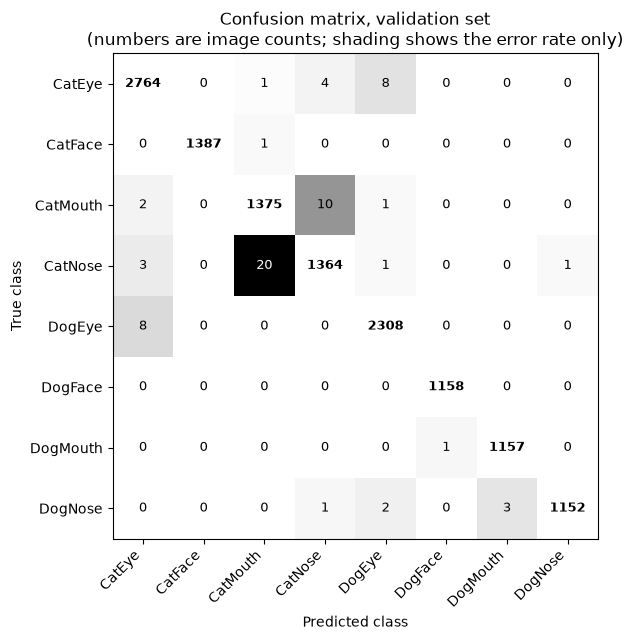

Misclassified validation images: 67 of 12732


,true class,predicted as,images
0,CatNose,CatMouth,20
1,CatMouth,CatNose,10
2,CatEye,DogEye,8
3,DogEye,CatEye,8
4,CatEye,CatNose,4
5,CatNose,CatEye,3
6,DogNose,DogMouth,3
7,CatMouth,CatEye,2


In [114]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
share = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
errors_only = share.copy()
np.fill_diagonal(errors_only, 0)                    # shade only the mistakes so that they stay visible

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(errors_only, cmap="Greys", vmin=0, vmax=max(errors_only.max(), 1e-9))
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(classes)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        dark = errors_only[i, j] > 0.6 * errors_only.max()
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9, color="white" if dark else "black",
                fontweight="bold" if i == j else "normal")
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title("Confusion matrix, validation set\n(numbers are image counts; shading shows the error rate only)")
plt.tight_layout(); plt.show()

pairs = [(classes[i], classes[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
top = pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:8], columns=["true class", "predicted as", "images"])
print(f"Misclassified validation images: {int((y_true != y_pred).sum())} of {len(y_true)}")
display(top)

## 4. Kaggle submission file

In [115]:
final_sub = pd.read_csv(FINAL_SUBMISSION)
assert list(final_sub.columns) == list(sub.columns), "columns must match the sample submission"
assert len(final_sub) == len(sub), (len(final_sub), len(sub))
assert final_sub["image_id"].tolist() == sub["image_id"].tolist(), "ids must match the sample submission order"
assert set(final_sub["class"]) <= set(classes), "unknown class name in the submission"
assert final_sub.notna().all().all(), "missing values in the submission"
print(f"{FINAL_SUBMISSION}: {len(final_sub)} rows, columns {list(final_sub.columns)}, format checked against sample_submission.csv")

mix = pd.DataFrame({
    "training %": (100 * train_df["label"].value_counts(normalize=True)).round(2),
    "validation %": (100 * val_df["label"].value_counts(normalize=True)).round(2),
    "predicted test %": (100 * final_sub["class"].value_counts(normalize=True)).round(2)}).loc[classes]
display(mix)

submission_task4.csv: 29443 rows, columns ['image_id', 'class'], format checked against sample_submission.csv


,training %,validation %,predicted test %
CatEye,21.81,21.81,21.62
CatFace,10.91,10.90,10.57
CatMouth,10.91,10.90,11.11
CatNose,10.90,10.91,9.84
DogEye,18.19,18.19,18.60
DogFace,9.10,9.10,9.59
DogMouth,9.10,9.10,9.69
DogNose,9.10,9.10,8.98


## 5. Validation compared with the Kaggle leaderboard

In [116]:
history_baseline = pd.read_csv(HISTORY_FILE)
rows = []
for name, hist in [("baseline", history_baseline), ("improvement run", history_final)]:
    best = hist.loc[hist["val_acc"].idxmax()]
    kaggle = KAGGLE_PUBLIC[name]
    rows.append({"model": name, "validation accuracy": round(best["val_acc"], 4), "validation loss": round(best["val_loss"], 4),
                 "Kaggle public score": kaggle, "difference (points)": round(100 * (best["val_acc"] - kaggle), 2)})
display(pd.DataFrame(rows))

,model,validation accuracy,validation loss,Kaggle public score,difference (points)
0,baseline,0.9878,0.0355,0.9662,2.16
1,improvement run,0.9947,0.0152,0.9723,2.24


# Task 6: Results Analysis and Improvement Strategies

Run task 1 to 5 first

The answers to the six key questions are each given in a separate section below.
1. **How reliable is the validation score, and is the improvement run really better than the baseline?** (confidence interval and McNemar test)
2. **What kind of mistakes are made?** ( wrong animal, wrong facial feature, or both)
3. **Do small images explain the errors, and the gap to the Kaggle score?** (accuracy by image size, then the validation accuracy re-weighted to the size mix of the test set)
4. **Which images are misclassified?** ( gallery of the most confident errors, to see whether they are model errors or label problems)
5. **Would cheap changes help?** (Ensemble of both models as well as simple horizontal-flip test-time augmentation. Both things are tested on the validation set only. If they improve then it was worth writing that one additional line of code.)
6. **Did augmentation help?** ( one extra training run with augmentation switched off, otherwise identical to the improvement run)

## 1. Ablation run: the improvement run without augmentation

The model, parts, learning rate, cosine scheduler, number of epochs, patience and seed all remain the same as in the Task 4 improvement run. The only change is that the training images are now run through the plain validation/test transform (i.e. just resize + normalize) instead of the usual augmentation transform. So any difference here must be due to augmentation. One run with one seed as ever, so small differences here are down to normal run-to-run noise.

Found best_model_task6_noaug.pt and history_task6_noaug.csv: training skipped.


,epoch,train_loss,train_acc,val_loss,val_acc,lr,seconds
0,1,0.0943,0.9688,0.0317,0.9914,0.0003,771.8114
1,2,0.0302,0.9899,0.0261,0.9912,0.0003,758.4170
2,3,0.0143,0.9953,0.0277,0.9916,0.0002,757.1832
3,4,0.0057,0.9982,0.0230,0.9941,0.0001,756.3029
4,5,0.0017,0.9994,0.0190,0.9954,0.0000,773.3789


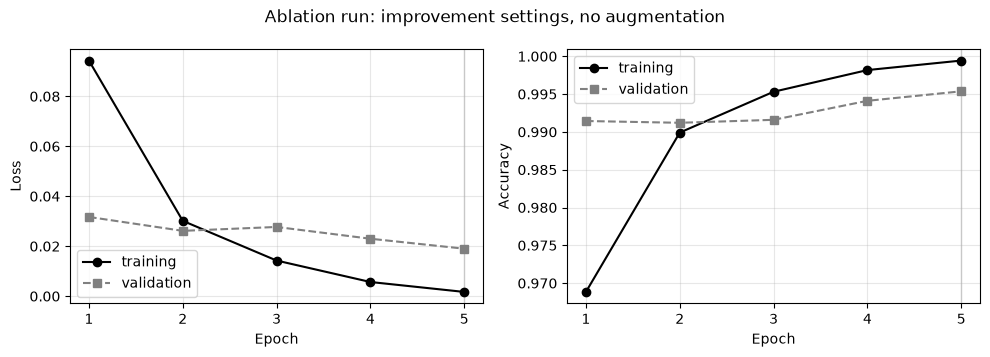

No augmentation: best validation accuracy 0.9954 (epoch 5), final training accuracy 0.9994, final validation accuracy 0.9954 (training minus validation: +0.41 points)
   training loss fell in every epoch: True;  validation loss rose in epochs: [3]
With augmentation (improvement run): best validation accuracy 0.9947 (epoch 5), final training accuracy 0.9951, final validation accuracy 0.9947 (training minus validation: +0.04 points)
   training loss fell in every epoch: True;  validation loss rose in epochs: none


In [124]:
NOAUG_WEIGHTS = "best_model_task6_noaug.pt"
NOAUG_HISTORY = "history_task6_noaug.csv"

if os.path.exists(NOAUG_WEIGHTS) and os.path.exists(NOAUG_HISTORY):
    history_noaug = pd.read_csv(NOAUG_HISTORY)
    print(f"Found {NOAUG_WEIGHTS} and {NOAUG_HISTORY}: training skipped.")
else:
    noaug_loader = make_loader(ImageDataset(train_df["path"], train_df["y"], eval_tf), shuffle=True)
    torch.manual_seed(SEED)
    model_noaug = build_finetune_model().to(device)
    history_noaug = train_model(model_noaug, noaug_loader, fit_val_loader, EPOCHS_T4, LEARNING_RATE_T4, WEIGHT_DECAY_T4,
        scheduler_fn=lambda opt: CosineAnnealingLR(opt, T_max=EPOCHS_T4),
        patience=PATIENCE, weights_file=NOAUG_WEIGHTS)
    history_noaug["lr"] = [LEARNING_RATE_T4] + history_noaug["lr"].tolist()[:-1]     # same shift as in Task 4
    history_noaug.to_csv(NOAUG_HISTORY, index=False)

display(history_noaug.round(4))
plot_history(history_noaug, "Ablation run: improvement settings, no augmentation")
summarise(history_noaug, "No augmentation")
summarise(history_final, "With augmentation (improvement run)")

In [125]:
# Kaggle file for the ablation run, so that its public score can be compared with the improvement run (about 3.5 minutes)
SUBMISSION_FILE_NOAUG = "submission_task6_noaug.csv"
model_noaug_best = load_trained(NOAUG_WEIGHTS)
ids_na, preds_na = predict_test(model_noaug_best, fit_test_loader)
submission_noaug = pd.DataFrame({"image_id": ids_na, "class": [idx_to_class[p] for p in preds_na]})
if not DEBUG_N:
    assert list(submission_noaug.columns) == list(sub.columns), "columns must match the sample submission"
    assert submission_noaug["image_id"].tolist() == sub["image_id"].tolist(), "ids must match the sample submission order"
submission_noaug.to_csv(SUBMISSION_FILE_NOAUG, index=False)
print(f"Wrote {SUBMISSION_FILE_NOAUG}: {len(submission_noaug)} rows")

Wrote submission_task6_noaug.csv: 29443 rows


## 2. Model outputs on the validation set

In [126]:
import math
from collections import OrderedDict

@torch.no_grad()
def predict_probs(model, loader, flip=False):
    """Softmax probabilities for every image in the loader. With flip=True the horizontally flipped image is also scored."""
    out, out_flip = [], []
    for xb, _ in loader:
        xb = xb.to(device)
        with torch.autocast(device_type=device, enabled=use_amp):
            out.append(torch.softmax(model(xb).float(), 1).cpu())
            if flip:
                out_flip.append(torch.softmax(model(torch.flip(xb, dims=[3])).float(), 1).cpu())
    p = torch.cat(out).numpy()
    return (p, torch.cat(out_flip).numpy()) if flip else p

probs_final, probs_final_flip = predict_probs(final_model, fit_val_loader, flip=True)
baseline_model = load_trained(BEST_WEIGHTS)
probs_base = predict_probs(baseline_model, fit_val_loader)
probs_noaug = predict_probs(load_trained(NOAUG_WEIGHTS), fit_val_loader)

n_val = len(y_true)
v = val_df.iloc[:n_val].copy()                      # validation table in loader order (the loader does not shuffle)
v["y"] = y_true
v["pred"] = probs_final.argmax(1)
v["conf"] = probs_final.max(1)
v["correct"] = v["y"] == v["pred"]
print(f"Agreement with the Task 5 predictions: {(v['pred'].values == y_pred).mean():.4f}")
print(f"Improvement run: {int(v['correct'].sum())} of {n_val} correct ({v['correct'].mean():.4f});  "
      f"baseline: {int((probs_base.argmax(1) == y_true).sum())} of {n_val} correct ({(probs_base.argmax(1) == y_true).mean():.4f})")

Agreement with the Task 5 predictions: 1.0000
Improvement run: 12665 of 12732 correct (0.9947);  baseline: 12577 of 12732 correct (0.9878)


## 3. How reliable is the validation score, and is the improvement real?

The Wilson interval gives us an estimate of how much the validation accuracy could change just due to random sampling. For McNemar’s exact test is only looking at the images where the two models disagreed. For the improvement run to be no better than the baseline case, each of these disagreements would have to be split equally between the two models.

In [127]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

def mcnemar_exact(b, c):
    """Two-sided exact p-value; b and c are the images only one of the two models gets right."""
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)

base_ok = probs_base.argmax(1) == y_true
final_ok = v["correct"].values
rows = []
for name, ok_vec, kag in [("baseline", base_ok, KAGGLE_PUBLIC["baseline"]), ("improvement run", final_ok, KAGGLE_PUBLIC["improvement run"])]:
    lo, hi = wilson(int(ok_vec.sum()), n_val)
    rows.append({"model": name, "validation accuracy": round(ok_vec.mean(), 4), "95% interval": f"{lo:.4f} to {hi:.4f}",
                 "Kaggle public score": kag, "gap to validation (points)": round(100 * (ok_vec.mean() - kag), 2)})
display(pd.DataFrame(rows))

only_final = int((final_ok & ~base_ok).sum())       # improvement right, baseline wrong
only_base = int((~final_ok & base_ok).sum())        # baseline right, improvement wrong
both_wrong = int((~final_ok & ~base_ok).sum())
print(f"Only the improvement run is right: {only_final};  only the baseline is right: {only_base};  both wrong: {both_wrong}")
print(f"McNemar exact test p-value: {mcnemar_exact(only_final, only_base):.2g}")
print(f"The validation interval is about +/-{50 * (wilson(int(final_ok.sum()), n_val)[1] - wilson(int(final_ok.sum()), n_val)[0]):.2f} points, "
      f"so sampling noise on validation cannot explain a gap of {100 * (final_ok.mean() - KAGGLE_PUBLIC['improvement run']):.2f} points.")

,model,validation accuracy,95% interval,Kaggle public score,gap to validation (points)
0,baseline,0.9878,0.9858 to 0.9896,0.9662,2.16
1,improvement run,0.9947,0.9933 to 0.9959,0.9723,2.24


Only the improvement run is right: 118;  only the baseline is right: 30;  both wrong: 37
McNemar exact test p-value: 1.5e-13
The validation interval is about +/-0.13 points, so sampling noise on validation cannot explain a gap of 2.24 points.


## 4. What kind of mistakes are made?

All mistake are in the form of an animal followed by a facial feature. This means a mistake can be misidentified for an animal or for a facial feature or both.
s

In [128]:
true_name = v["y"].map(idx_to_class)
pred_name = v["pred"].map(idx_to_class)
split_name = lambda s: (s[:3], s[3:])
t_animal, t_feat = zip(*[split_name(s) for s in true_name]); p_animal, p_feat = zip(*[split_name(s) for s in pred_name])
v["animal_ok"] = np.array(t_animal) == np.array(p_animal)
v["feature_ok"] = np.array(t_feat) == np.array(p_feat)

err = v[~v["correct"]]
kinds = OrderedDict([
    ("right animal, wrong feature", int((err["animal_ok"] & ~err["feature_ok"]).sum())),
    ("wrong animal, right feature", int((~err["animal_ok"] & err["feature_ok"]).sum())),
    ("wrong animal and wrong feature", int((~err["animal_ok"] & ~err["feature_ok"]).sum()))])
kind_table = pd.DataFrame({"errors": kinds}); kind_table["share of errors (%)"] = (100 * kind_table["errors"] / max(len(err), 1)).round(1)
display(kind_table)

pair_counts = err.groupby([true_name[err.index].rename("true class"), pred_name[err.index].rename("predicted as")]).size().sort_values(ascending=False)
display(pair_counts.head(8).rename("images").reset_index())

,errors,share of errors (%)
"right animal, wrong feature",47,70.1
"wrong animal, right feature",18,26.9
wrong animal and wrong feature,2,3.0


,true class,predicted as,images
0,CatNose,CatMouth,20
1,CatMouth,CatNose,10
2,DogEye,CatEye,8
3,CatEye,DogEye,8
4,CatEye,CatNose,4
5,DogNose,DogMouth,3
6,CatNose,CatEye,3
7,CatMouth,CatEye,2


## 5. Do small images explain the errors, and the gap to the Kaggle score?

For Task 1, we found that many images were small, and the test set had a higher percentage of small images than the training set. The validation accuracy is graphed as a function of shortest image side. The accuracy for each size group is averaged together using the size mix of the **test** images. So this averages together using the size mix of the images that would be used for a test, and shows you the accuracy that you would expect on the test set if the only difference between the validation set and the test set were image size.

,images,errors,accuracy,share of validation (%),share of test (%),share of all errors (%)
size group,,,,,,
under 32,837,18,0.9785,6.6,8.2,26.9
32 to 47,1937,10,0.9948,15.2,15.4,14.9
48 to 63,1915,7,0.9963,15.0,16.8,10.4
64 to 95,2994,8,0.9973,23.5,21.9,11.9
96 to 127,1910,12,0.9937,15.0,13.9,17.9
128 and over,3139,12,0.9962,24.7,23.8,17.9


Validation accuracy: 0.9947
Validation accuracy re-weighted to the test size mix: 0.9944
Kaggle public score: 0.9723
Part of the gap explained by image sizes: 0.03 of 2.24 points


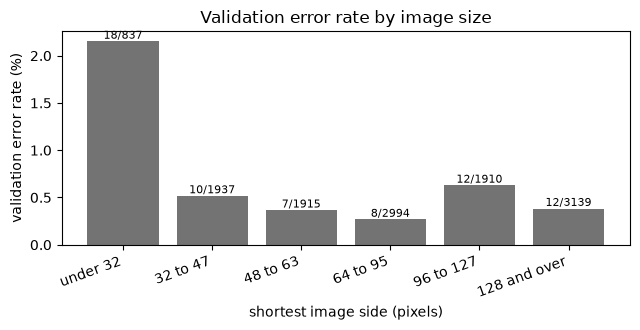

In [129]:
def shortest_side(p):
    with Image.open(p) as im:
        return min(im.size)

BINS = [0, 32, 48, 64, 96, 128, 10**6]
LABELS = ["under 32", "32 to 47", "48 to 63", "64 to 95", "96 to 127", "128 and over"]
v["short"] = [shortest_side(p) for p in v["path"]]
v["size group"] = pd.cut(v["short"], bins=BINS, labels=LABELS, right=False)
test_short = pd.Series([shortest_side(p) for p in test_files])
test_group = pd.cut(test_short, bins=BINS, labels=LABELS, right=False)

by_size = v.groupby("size group", observed=False).agg(images=("correct", "size"), errors=("correct", lambda s: int((~s).sum())))
by_size["accuracy"] = (1 - by_size["errors"] / by_size["images"]).round(4)
by_size["share of validation (%)"] = (100 * by_size["images"] / by_size["images"].sum()).round(1)
by_size["share of test (%)"] = (100 * test_group.value_counts(normalize=True).reindex(LABELS)).round(1).values
by_size["share of all errors (%)"] = (100 * by_size["errors"] / by_size["errors"].sum()).round(1)
display(by_size)

usable = by_size["images"] > 0
expected_test = float((by_size.loc[usable, "accuracy"] * by_size.loc[usable, "share of test (%)"] / by_size.loc[usable, "share of test (%)"].sum()).sum())
print(f"Validation accuracy: {final_ok.mean():.4f}")
print(f"Validation accuracy re-weighted to the test size mix: {expected_test:.4f}")
print(f"Kaggle public score: {KAGGLE_PUBLIC['improvement run']:.4f}")
print(f"Part of the gap explained by image sizes: {100 * (final_ok.mean() - expected_test):.2f} of {100 * (final_ok.mean() - KAGGLE_PUBLIC['improvement run']):.2f} points")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(range(len(LABELS)), 100 * (1 - by_size["accuracy"]).values, color="0.45")
ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(LABELS, rotation=20, ha="right")
ax.set_ylabel("validation error rate (%)"); ax.set_xlabel("shortest image side (pixels)")
for i, (n, e) in enumerate(zip(by_size["images"], by_size["errors"])):
    ax.text(i, 100 * e / max(n, 1), f"{e}/{n}", ha="center", va="bottom", fontsize=8)
ax.set_title("Validation error rate by image size"); plt.tight_layout(); plt.show()

## 6. Which images are misclassified?

Confident mistakes of the gallery are shown first. These are either hard images or images with uncertain labels. It makes sense to look at these images first before investing in a larger model to verify uncertain labels. The table differentiates between all errors and the confidence the network had for wrong classifications.

conf,under 0.7,0.7 to 0.9,0.9 or more
errors,28,22,17


Mean confidence: correct predictions 0.997,  wrong predictions 0.753


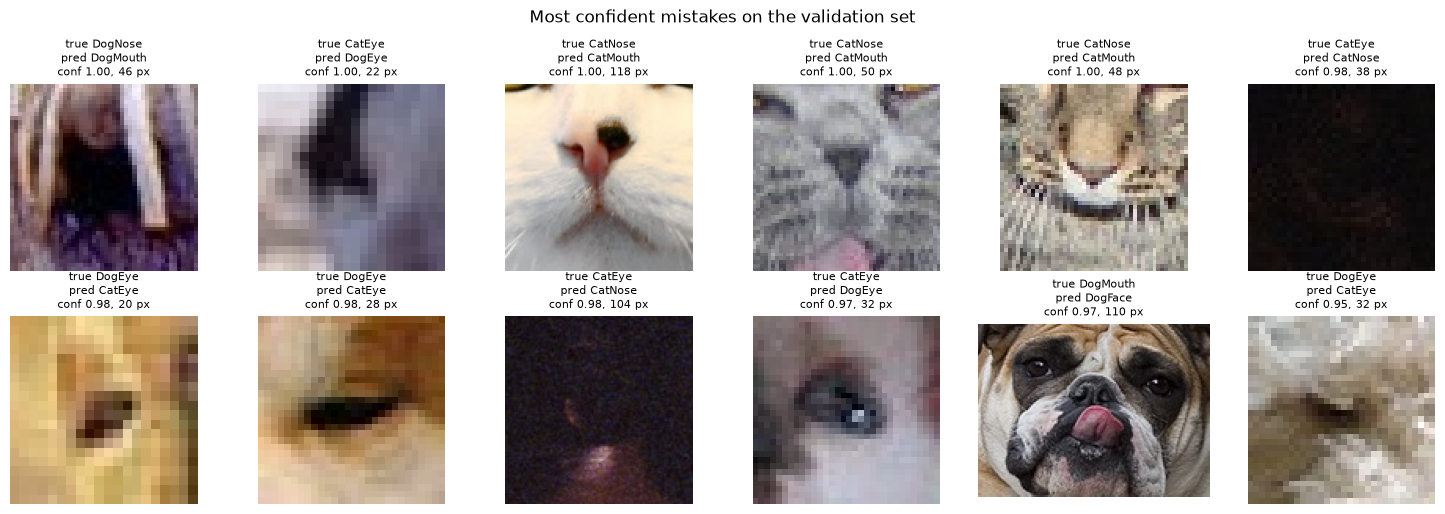

In [130]:
err = v[~v["correct"]]                                # rebuilt so that it includes the image sizes added above
conf_bins = pd.cut(err["conf"], bins=[0, 0.7, 0.9, 1.0001], labels=["under 0.7", "0.7 to 0.9", "0.9 or more"], right=False)
display(pd.DataFrame({"errors": conf_bins.value_counts().reindex(["under 0.7", "0.7 to 0.9", "0.9 or more"])}).T)
print(f"Mean confidence: correct predictions {v.loc[v['correct'], 'conf'].mean():.3f},  wrong predictions {err['conf'].mean():.3f}")

show = err.sort_values("conf", ascending=False).head(12)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
for ax, (_, r) in zip(axes.ravel(), show.iterrows()):
    ax.imshow(Image.open(r["path"]).convert("RGB")); ax.axis("off")
    ax.set_title(f"true {idx_to_class[r['y']]}\npred {idx_to_class[r['pred']]}\nconf {r['conf']:.2f}, {int(r['short'])} px", fontsize=8)
plt.suptitle("Most confident mistakes on the validation set"); plt.tight_layout(); plt.show()

## 7. Would cheap changes help?

We can make two very cheap changes and measure them on the validation set: averaging the probabilities between the baseline and improved model (a two-model ensemble), and averaging the score on an image with its horizontal mirror image (test-time augmentation). Note that these were selected on the validation set, so there will be some indication of improvement on the Kaggle test set, but that will have to be confirmed there.

In [131]:
def acc(p):
    return float((p.argmax(1) == y_true).mean())

variants = OrderedDict([
    ("baseline", probs_base),
    ("improvement run", probs_final),
    ("improvement run + flipped image", (probs_final + probs_final_flip) / 2),
    ("baseline + improvement run", (probs_base + probs_final) / 2),
])
res = pd.DataFrame({"validation accuracy": {k: acc(p) for k, p in variants.items()}})
res["errors"] = [int((p.argmax(1) != y_true).sum()) for p in variants.values()]
res["change in errors vs improvement run"] = res["errors"] - int((~final_ok).sum())
display(res.round(4))

,validation accuracy,errors,change in errors vs improvement run
baseline,0.9878,155,88
improvement run,0.9947,67,0
improvement run + flipped image,0.9952,61,-6
baseline + improvement run,0.9950,64,-3


## 8. Did augmentation help?

Same images scored by improvement run (with augmentation) and by ablation run (without augmentation). McNemar’s exact test is used to test the pairs of scores, and the difference of training accuracy versus validation accuracy for each run indicates whether it still develops overfitting or not.

In [132]:
noaug_ok = probs_noaug.argmax(1) == y_true
only_aug = int((final_ok & ~noaug_ok).sum()); only_noaug = int((~final_ok & noaug_ok).sum())
lo, hi = wilson(int(noaug_ok.sum()), n_val)
print(f"Without augmentation: validation accuracy {noaug_ok.mean():.4f} (95% interval {lo:.4f} to {hi:.4f}), {int((~noaug_ok).sum())} errors")
print(f"With augmentation:    validation accuracy {final_ok.mean():.4f}, {int((~final_ok).sum())} errors")
print(f"Only the augmented run is right: {only_aug};  only the run without augmentation is right: {only_noaug}")
print(f"McNemar exact test p-value: {mcnemar_exact(only_aug, only_noaug):.2g}")

best_a, best_n = history_final.loc[history_final["val_acc"].idxmax()], history_noaug.loc[history_noaug["val_acc"].idxmax()]
display(pd.DataFrame({
    "with augmentation": [best_a["train_acc"], best_a["val_acc"], best_a["val_loss"]],
    "without augmentation": [best_n["train_acc"], best_n["val_acc"], best_n["val_loss"]]},
    index=["training accuracy (best epoch)", "validation accuracy", "validation loss"]).round(4))
print(f"Training minus validation accuracy at the best epoch: with augmentation {100 * (best_a['train_acc'] - best_a['val_acc']):+.2f} points, "
      f"without {100 * (best_n['train_acc'] - best_n['val_acc']):+.2f} points")

Without augmentation: validation accuracy 0.9954 (95% interval 0.9940 to 0.9964), 59 errors
With augmentation:    validation accuracy 0.9947, 67 errors
Only the augmented run is right: 28;  only the run without augmentation is right: 36
McNemar exact test p-value: 0.38


,with augmentation,without augmentation
training accuracy (best epoch),0.9951,0.9994
validation accuracy,0.9947,0.9954
validation loss,0.0152,0.0190


Training minus validation accuracy at the best epoch: with augmentation +0.04 points, without +0.41 points


## 9․ Discussion

- **Validation and Kaggle results**․ The new method outperforms the original on both validation and Kaggle data (validation 0․9947 vs․ 0․9878; p = 1․5e-13 by McNemar's test; Kaggle 0․9723 vs․ 0․9662)․ Kaggle results are consistently 2․2 points lower on Kaggle than on the validation set‚ much more than the sampling error of ±0․13 points on the validation set․ This suggests that the test and validation sets are quite different․
- **Differences in image size cannot explain the gap in results**․ Images with a height or width less than 32 pixels have the worst validation accuracy (0․9785) and represent 26․9% of the test errors‚ but adjusting the validation accuracy to represent the test image size distribution only decreases the validation accuracy from 0․9947 to 0․9944․
- **Errors**․ 70․1% of errors involve correct animal‚ wrong attribute․ CatNose and CatMouth account for 30 of 67 errors․ Examples of confident errors are small and dark images‚ partially cropped images containing multiple attributes‚ and images with questionably labeled attributes․
- **Augmentation**․ Validation accuracy is 0․9954 without image augmentation (not statistically significant‚ p = 0․38)․ Kaggle score is 0․9668 without image augmentation versus 0․9723․ Validation accuracy does not show benefits of image augmentation․ Training accuracy is 0․9994 without image augmentation‚ suggesting more overfitting to the training data․
- **Cheap changes**․ Ensemble methods and mirroring test data cut validation error by 3 to 6․ Improvements from these methods are modest relative to test-retest variability․
- **Next steps**․ Other techniques to test for validation errors (near-duplicates‚ k-fold‚ and adversarial validation)․ Other changes to training data․ More or different fine-tuning techniques․ Use of a larger training data set or model․ Other analyzes of erroneous predictions․